In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Preprocessing

In [6]:
built_up = pd.read_csv('/kaggle/input/remote-sensing-data/BuiltUpArea_Jawa.csv')
night = pd.read_csv('/kaggle/input/remote-sensing-data/NightLight_Jawa_2023.csv')
ndvi = pd.read_csv('/kaggle/input/remote-sensing-data/NDVI_Jawa_2023.csv')
lst = pd.read_csv('/kaggle/input/remote-sensing-data/LST_Jawa_2023.csv')
green_area = pd.read_csv('/kaggle/input/remote-sensing-data/GreenArea_Jawa.csv')
area = pd.read_csv('/kaggle/input/remote-sensing-data/TotalArea_Jawa.csv')
se = pd.read_csv('/kaggle/input/unityyy/variabel baru  - Sheet2.csv',header=1)

se = pd.read_csv('/kaggle/input/unityyy/variabel baru  - Sheet2.csv',header=0)
se.drop(index=0,inplace=True)

column_rename_map = {
    # Sosial
    'Kepadatan Penduduk/km2_2022': 'X1',
    'Rata-Rata Lama Sekolah_2023': 'X7',
    'Tingkat Pengangguran Terbuka_2024': 'X8',
    'Angka Harapan Hidup_2023': 'X9',
    'Angka Kematian Bayi_2020': 'X10',
    'Persentase Rumah Tangga yang Menempati Rumah Layak Huni Menurut Kabupaten/Kota_2022': 'X11',
    'Indeks Ketimpangan Gender_2024': 'X12',

    # Ekonomi
    'PDRB Perkapita Menurut Kabupaten/Kota (Ribu Rupiah)_2023': 'X5',
    'dana alokasi umum_2025': 'X6',
    'Prevalensi Ketidakcukupan Konsumsi Pangan (Persen) Per Kabupaten/kota (Persen)_2024': 'X13',
    'Indeks Kemahalan Konstruksi Kabupaten/Kota_2024': 'X14',
    'Persentase Penduduk Miskin_2024': 'X15',

    # Lingkungan
    'Indeks Kualitas Udara_2025': 'X16',
    'Persentase Rumah Tangga yang Memiliki Akses Terhadap Sumber Air Layak_2022': 'X17',
    'Indeks Kualitas Lingkungan Hidup_2022': 'X18',
    'Persentase Rumah Tangga yang Memiliki Akses Sanitasi Layak_2022': 'X19',
}
se.drop(se.columns[10], axis=1,inplace=True)
se.drop(se.columns[17], axis=1,inplace=True)
se.drop(se.columns[9], axis=1,inplace=True)
se.drop(se.columns[11], axis=1,inplace=True)
se.rename(columns=column_rename_map, inplace=True)

for col in se.columns.to_list()[2:]:
    se[col] = se[col].replace('-', np.nan)
    se[col] = se[col].astype(str).str.replace(',', '.').astype(float)

In [7]:
remote_sensing = pd.DataFrame()
remote_sensing['Provinsi'] = area['ADM1_NAME']
remote_sensing['Kab/Kota'] = built_up['ADM2_NAME']
remote_sensing['Built_Area'] = built_up['sum']
remote_sensing['Night_Light'] = night['mean']
remote_sensing['NDVI'] = ndvi['mean']
remote_sensing['LST'] = lst['mean']
remote_sensing['Green_Area'] = green_area['sum']
remote_sensing['Luas_Area'] = area['sum']
remote_sensing['Built_Area'] = remote_sensing['Built_Area']/remote_sensing['Luas_Area']
remote_sensing['Green_Area'] = remote_sensing['Green_Area']/remote_sensing['Luas_Area']
remote_sensing.drop(columns=['Luas_Area'],inplace=True)

column_rename_map = {
    'Night_Light': 'X2',
    'Built_Area': 'X3',
    'NDVI': 'X20',
    'LST': 'X4',
    'Green_Area': 'X21',
}

remote_sensing.rename(columns=column_rename_map, inplace=True)

In [8]:
kabkota_rename_map = {
    'Gunung Kidul': 'Gunungkidul',
    'Kulon Progo': 'Kulonprogo',
}

se['Kab/Kota'] = se['Kab/Kota'].replace(kabkota_rename_map)
df = pd.merge(remote_sensing,se.drop(columns=['Provinsi']), on=['Kab/Kota'], how='inner')
df = df[['Provinsi', 'Kab/Kota'] + sorted([col for col in df.columns if col not in ['Provinsi', 'Kab/Kota']])]
df

,Provinsi,Kab/Kota,X1,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X2,X20,X21,X3,X4,X5,X6,X7,X8,X9
0,Dki Jakarta,Kota Jakarta Utara,13327.0019,11.2800,22.9300,0.1550,3.3900,112.6400,6.4400,107.0000,96.0900,43.6700,88.9200,31.7568,0.2435,0.0714,0.7152,36.4803,348893.0000,63745532.0000,10.8500,6.1800,73.6750
1,Jawa Timur,Kota Batu,1580.6348,12.1200,83.6400,0.1880,3.4900,99.8800,3.0600,80.0000,99.1200,75.2700,94.3700,3.2845,0.6724,0.6979,0.0906,24.8852,93214.3000,511190380.0000,9.8500,3.6300,73.2900
2,Jawa Timur,Malang,751.4438,12.1400,69.4800,0.3150,9.4200,98.8600,8.9800,91.0000,96.0200,67.5200,81.8000,1.5312,0.6974,0.8331,0.0481,27.8232,47272.2000,1932402330.0000,7.7500,5.1300,73.2600
3,Jawa Barat,Bandung,2067.8511,13.6000,52.5800,0.3870,5.8000,111.3000,6.1900,NaN,93.7900,62.2300,69.1200,2.1803,0.6335,0.6746,0.0934,27.2452,41372.0000,2607774432.0000,9.1000,6.3600,74.2700
4,Jawa Barat,Kota Cimahi,14315.2534,12.1200,53.7700,0.1620,5.4300,112.9400,4.3900,82.0000,97.8100,48.0000,76.4400,14.5120,0.3203,0.1237,0.8359,34.7624,68552.0000,604161949.0000,11.3900,8.9700,74.8000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,Jawa Barat,Subang,844.4352,14.3900,68.2800,0.4320,6.1900,105.3300,9.4900,93.0000,98.0100,55.6900,90.2900,1.6979,0.5788,0.4245,0.0578,30.9001,30120.0000,1380848245.0000,7.4500,6.7300,73.2400
110,Jawa Barat,Sukabumi,659.3342,14.7300,42.4800,0.5330,5.8200,103.1200,6.8700,59.0000,85.7000,61.6000,51.9000,0.7982,0.7104,0.8522,0.0209,28.0593,29374.0000,1910786931.0000,7.3300,7.1100,71.8300
111,Jawa Barat,Sumedang,774.5470,13.1300,66.7500,0.2170,5.4300,103.4700,9.1000,90.0000,95.8400,63.3500,77.3200,1.2432,0.6650,0.7346,0.0438,29.1897,36773.0000,1174469109.0000,8.7300,6.1600,73.1900
112,Jawa Barat,Kota Bekasi,11959.5954,10.8000,54.3600,0.2730,4.8800,106.5900,4.0100,76.0000,98.2800,46.6300,99.0800,24.4369,0.3125,0.1912,0.7283,37.7716,45281.0000,1477177456.0000,11.6600,7.8200,75.7900


In [9]:
x11_avg = df['X11'].mean()
x16_avg = df['X16'].mean()

df['X11'].fillna(x11_avg,inplace=True)
df['X16'].fillna(x16_avg,inplace=True)

## Entropy

In [10]:
attribute_map_risiko = {
    # =========================
    # URBAN PRESSURE INDICATORS
    # =========================
    'X1': '+',  # Kepadatan Penduduk → tekanan spasial & sosial
    'X2': '+',  # Night Light Intensity → intensitas aktivitas ekonomi & ekspansi urban
    'X3': '+',  # Persentase Lahan Terbangun → ekspansi fisik kota
    'X4': '+',  # LST → tekanan termal akibat permukaan terbangun & minim vegetasi
    'X5': '+',  # PDRB Perkapita → kapasitas ekonomi
    'X6': '+',  # Dana Alokasi Umum → kapasitas fiskal daerah

    # ==========================
    # VULNERABILITY INDICATORS
    # ==========================
    'X7': '-',  # Rata-Rata Lama Sekolah → kapabilitas sosial
    'X8': '+',  # Pengangguran → rentan ekonomi
    'X9': '-',  # Harapan Hidup → kapabilitas kesehatan
    'X10': '+',  # Kematian Bayi → rentan layanan kesehatan
    'X11': '-',  # Rumah Layak Huni → kualitas hidup
    'X12': '+',  # Ketimpangan Gender → ketimpangan sosial
    'X13': '+',  # Ketidakcukupan Pangan → kerawanan sosial
    'X14': '+',  # Kemahalan Konstruksi → beban hidup
    'X15': '+',  # Kemiskinan → kerentanan ekonomi
    'X16': '-',  # Indeks Kualitas Udara → degradasi akibat urban pressure
    'X17': '-',  # Akses Air Minum Layak → ketahanan infrastruktur dasar
    'X18': '-',  # Indeks Kualitas LH → kualitas lingkungan umum
    'X19': '-',  # Akses Sanitasi Layak → ketahanan sanitasi
    'X20': '-',  # NDVI → keberadaan vegetasi pelindung
    'X21': '-'   # Green Area Percentage → kapasitas ekologis
}

urban_pressure_vars = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6']
urban_vulnerability_vars = [f'X{i}' for i in range(7, 22)]

def shannon_entropy(df: pd.DataFrame, variabel_list: list) -> tuple:
    df_entropy = df[variabel_list].copy()

    # Normalisasi
    df_norm = pd.DataFrame(index=df_entropy.index)
    for col in df_entropy.columns:
        col_min = df_entropy[col].min()
        col_max = df_entropy[col].max()

        if col_max == col_min:
            df_norm[col] = 0
        elif attribute_map_risiko.get(col) == '+':
            df_norm[col] = (df_entropy[col] - col_min) / (col_max - col_min)
        elif attribute_map_risiko.get(col) == '-':
            df_norm[col] = (col_max - df_entropy[col]) / (col_max - col_min)
        else:
            df_norm[col] = (df_entropy[col] - col_min) / (col_max - col_min)

    # Hitung entropy
    proporsi = df_norm / df_norm.sum()
    k = 1 / np.log(len(df_entropy))
    entropy = -k * (proporsi * np.log(proporsi + 1e-10)).sum()
    redundansi = 1 - entropy
    bobot = redundansi / redundansi.sum()
    skor = (df_norm * bobot).sum(axis=1)

    # Buat DataFrame bobot
    df_weight = pd.DataFrame({
        'Variabel': df_entropy.columns,
        'Entropy': entropy.values,
        'Redundansi': redundansi.values,
        'Bobot': bobot.values
    })

    return skor, df_weight

# Hitung skor tekanan dan kerentanan
skor_pressure, bobot_pressure = shannon_entropy(df, urban_pressure_vars)
skor_vulnerability, bobot_vulnerability = shannon_entropy(df, urban_vulnerability_vars)

df_weights = pd.concat([
    bobot_pressure.assign(Dimensi='Urban_Pressure'),
    bobot_vulnerability.assign(Dimensi='Vulnerability')
])

df['Urban_Pressure'] = skor_pressure
df['Vulnerability_index'] = skor_vulnerability


In [11]:
df_weights[df_weights['Dimensi']=='Urban_Pressure']

,Variabel,Entropy,Redundansi,Bobot,Dimensi
0,X1,0.8328,0.1672,0.2268,Urban_Pressure
1,X2,0.8195,0.1805,0.2447,Urban_Pressure
2,X3,0.8497,0.1503,0.2038,Urban_Pressure
3,X4,0.9774,0.0226,0.0306,Urban_Pressure
4,X5,0.8088,0.1912,0.2593,Urban_Pressure
5,X6,0.9744,0.0256,0.0348,Urban_Pressure


In [12]:
df_weights[df_weights['Dimensi']=='Vulnerability']

,Variabel,Entropy,Redundansi,Bobot,Dimensi
0,X7,0.9707,0.0293,0.0480,Vulnerability
1,X8,0.9698,0.0302,0.0496,Vulnerability
2,X9,0.9680,0.0320,0.0524,Vulnerability
3,X10,0.9683,0.0317,0.0520,Vulnerability
4,X11,0.9667,0.0333,0.0546,Vulnerability
5,X12,0.9441,0.0559,0.0917,Vulnerability
6,X13,0.9615,0.0385,0.0631,Vulnerability
7,X14,0.9821,0.0179,0.0293,Vulnerability
8,X15,0.9671,0.0329,0.0540,Vulnerability
9,X16,0.9728,0.0272,0.0446,Vulnerability


In [13]:
df_weights.to_excel('weight.xlsx',index=False)

In [14]:
from sklearn.utils import resample

def bootstrap_entropy_stability(df: pd.DataFrame, var_list: list, n_iterations: int = 100, seed: int = 42):
    np.random.seed(seed)
    bobot_list = []

    for _ in range(n_iterations):
        df_sample = resample(df, replace=True)
        _, bobot_sample = shannon_entropy(df_sample, var_list)
        bobot_list.append(bobot_sample['Bobot'].values)

    bobot_array = np.array(bobot_list)
    bobot_mean = bobot_array.mean(axis=0)
    bobot_std = bobot_array.std(axis=0)
    bobot_cv = bobot_std / (bobot_mean + 1e-10)  # Coefficient of Variation (stabilitas relatif)

    # Ambil nama variabel dari hasil terakhir (boleh dari fungsi utama juga)
    variabel_names = bobot_sample['Variabel'].values

    df_eval = pd.DataFrame({
        'Variabel': variabel_names,
        'Bobot_Mean': bobot_mean,
        'Bobot_STD': bobot_std,
        'Bobot_CV': bobot_cv  # Semakin kecil CV, semakin stabil
    })

    return df_eval

In [15]:
df_eval_pressure = bootstrap_entropy_stability(df, urban_pressure_vars, n_iterations=100)
df_eval_vuln = bootstrap_entropy_stability(df, urban_vulnerability_vars, n_iterations=100)

df_eval_pressure['Dimensi'] = 'Urban_Pressure'
df_eval_vuln['Dimensi'] = 'Vulnerability'
df_eval = pd.concat([df_eval_pressure, df_eval_vuln], ignore_index=True)
df_eval

,Variabel,Bobot_Mean,Bobot_STD,Bobot_CV,Dimensi
0,X1,0.2300,0.0141,0.0615,Urban_Pressure
1,X2,0.2419,0.0081,0.0335,Urban_Pressure
2,X3,0.2041,0.0129,0.0632,Urban_Pressure
3,X4,0.0374,0.0094,0.2503,Urban_Pressure
4,X5,0.2514,0.0264,0.1050,Urban_Pressure
5,X6,0.0352,0.0072,0.2045,Urban_Pressure
6,X7,0.0474,0.0065,0.1365,Vulnerability
7,X8,0.0487,0.0072,0.1480,Vulnerability
8,X9,0.0501,0.0067,0.1329,Vulnerability
9,X10,0.0569,0.0083,0.1465,Vulnerability


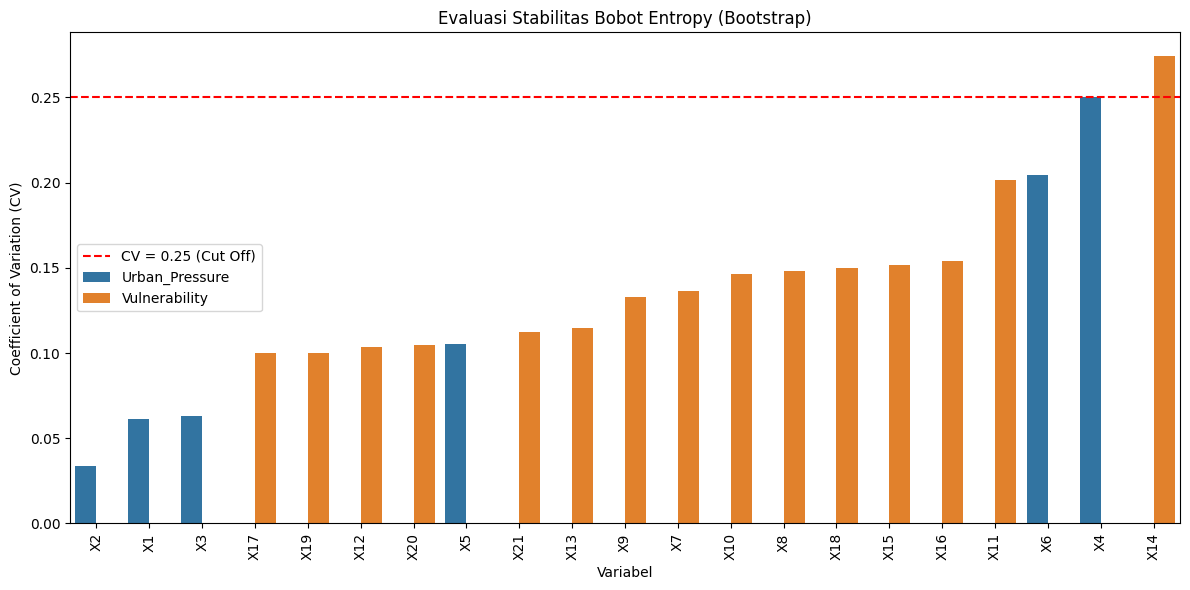

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.barplot(data=df_eval.sort_values('Bobot_CV'), x='Variabel', y='Bobot_CV', hue='Dimensi')
plt.axhline(0.25, color='red', linestyle='--', label='CV = 0.25 (Cut Off)')
plt.title('Evaluasi Stabilitas Bobot Entropy (Bootstrap)')
plt.ylabel('Coefficient of Variation (CV)')
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()


## Natural Breaks

In [17]:
!pip install jenkspy
import jenkspy

urban_scores = df['Urban_Pressure'].values
# urban_scores = urban_scores[urban_scores != urban_scores.max()]
n_classes = 3

breaks = jenkspy.jenks_breaks(urban_scores, n_classes=n_classes)
labels = ['Low', 'Medium', 'High']
df['Urban_Pressure_Level'] = pd.cut(df['Urban_Pressure'], bins=breaks, labels=labels, include_lowest=True)

vulneLrability_scores = df['Vulnerability_index'].values
n_classes = 3

breaks = jenkspy.jenks_breaks(vulneLrability_scores, n_classes=n_classes)
labels = ['Low', 'Medium', 'High']
df['Vulnerability_Level'] = pd.cut(df['Vulnerability_index'], bins=breaks, labels=labels, include_lowest=True)

In [18]:
def gvf(x, breaks):
    x = np.array(x)
    total_ssd = ((x - x.mean())**2).sum()

    grouped_ssd = 0
    for i in range(len(breaks) - 1):
        group = x[(x >= breaks[i]) & (x <= breaks[i+1])]
        if len(group) > 0:
            grouped_ssd += ((group - group.mean())**2).sum()

    gvf = 1 - (grouped_ssd / total_ssd)
    return gvf


breaks = jenkspy.jenks_breaks(urban_scores, n_classes=n_classes)
urban_gvf = gvf(df['Urban_Pressure'], breaks)

breaks = jenkspy.jenks_breaks(vulneLrability_scores, n_classes=n_classes)
vulnerability_gvf = gvf(df['Vulnerability_index'], breaks)

print(f"GVF Urban Pressure: {urban_gvf:.4f}")
print(f"GVF Vulnerability: {vulnerability_gvf:.4f}")

GVF Urban Pressure: 0.8841
GVF Vulnerability: 0.8262


In [19]:
def classify_risk_level(row):
    p = row['Urban_Pressure_Level']
    v = row['Vulnerability_Level']
    
    if p == 'High' and v == 'High':
        return 'Very High'
    elif (p == 'High' and v == 'Medium') or (p == 'Medium' and v == 'High'):
        return 'High'
    elif (p == 'Medium' and v == 'Medium') or (p == 'High' and v == 'Low') or (p == 'Low' and v == 'High'):
        return 'Moderate'
    else:
        return 'Low'

df['Urbanization_Risk_Level'] = df.apply(classify_risk_level, axis=1)


In [20]:
df[['Kab/Kota', 'Urban_Pressure','Vulnerability_index','Urban_Pressure_Level','Vulnerability_Level','Urbanization_Risk_Level']].sort_values(by='Urban_Pressure', ascending=False).head(60)

,Kab/Kota,Urban_Pressure,Vulnerability_index,Urban_Pressure_Level,Vulnerability_Level,Urbanization_Risk_Level
15,Kota Jakarta Pusat,0.9644,0.3907,High,Medium,High
14,Kota Jakarta Barat,0.6777,0.3814,High,Medium,High
16,Kota Jakarta Selatan,0.6277,0.3105,High,Medium,High
0,Kota Jakarta Utara,0.6016,0.4239,High,High,Very High
17,Kota Jakarta Timur,0.5784,0.3569,High,Medium,High
102,Kota Bandung,0.5107,0.4319,High,High,Very High
11,Kota Yogyakarta,0.5060,0.3557,High,Medium,High
35,Kota Surakarta,0.4946,0.3292,High,Medium,High
94,Kota Tangerang,0.4827,0.3466,High,Medium,High
112,Kota Bekasi,0.4753,0.3529,High,Medium,High


In [21]:
from sklearn.metrics import silhouette_score

print(silhouette_score(df[urban_pressure_vars],df['Urban_Pressure_Level']))

print(silhouette_score(df[urban_vulnerability_vars],df['Vulnerability_Level']))

0.20489409162299457
0.04703748278922527


## Spatial Analysis

In [22]:
!pip install geopandas libpysal esda splot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.8/142.8 kB 3.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 31.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.9/389.9 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.7/322.7 kB 13.4 MB/s eta 0:00:00
  Attempting uninstall: libpysal
    Found existing installation: libpysal 4.9.2
    Uninstalling libpysal-4.9.2:
      Successfully uninstalled libpysal-4.9.2


In [23]:
import geopandas as gpd
from libpysal.weights import Queen
from esda.moran import Moran
from esda.moran import Moran_Local
from splot.esda import lisa_cluster
from libpysal.weights import KNN
from shapely.geometry import Polygon, MultiPolygon

gdf = gpd.read_file("/kaggle/input/peta-jawa/GAUL_Kota_Indonesia_terpilih (1).geojson")
gdf = gdf.merge(df[['Kab/Kota','Urban_Pressure','Urban_Pressure_Level','Vulnerability_index','Vulnerability_Level','Urbanization_Risk_Level']], left_on='ADM2_NAME', right_on='Kab/Kota')

In [24]:
def extract_first_polygon(geom):
    if geom.geom_type == 'GeometryCollection':
        for part in geom.geoms:
            if isinstance(part, (Polygon, MultiPolygon)):
                return part
        return None
    else:
        return geom

gdf['geometry'] = gdf['geometry'].apply(extract_first_polygon)


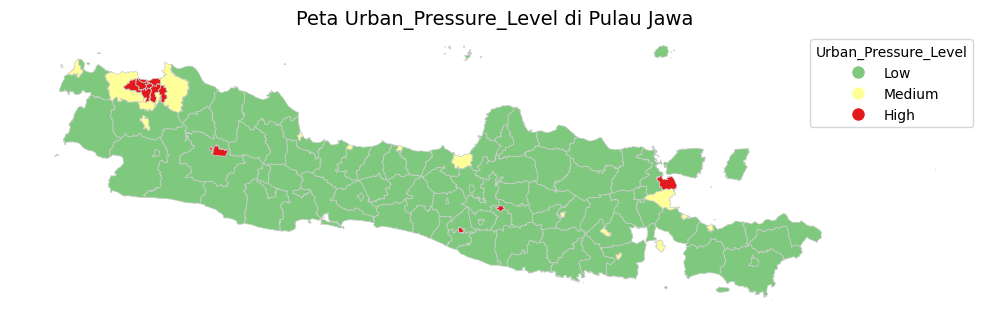

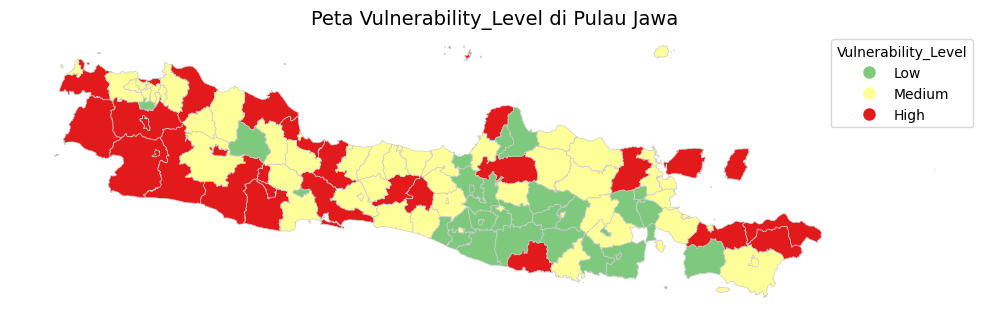

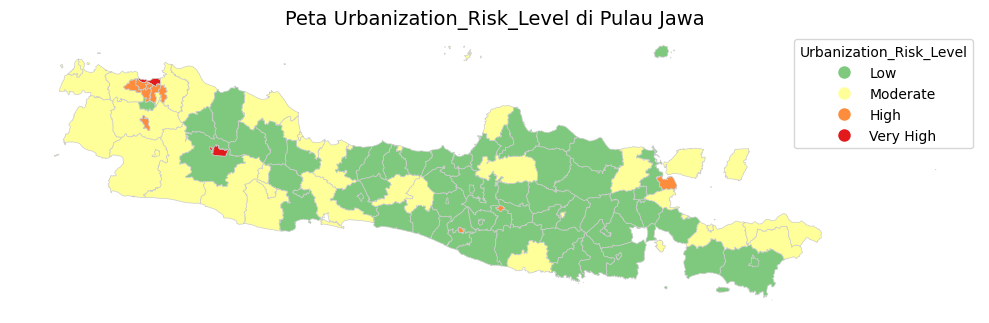

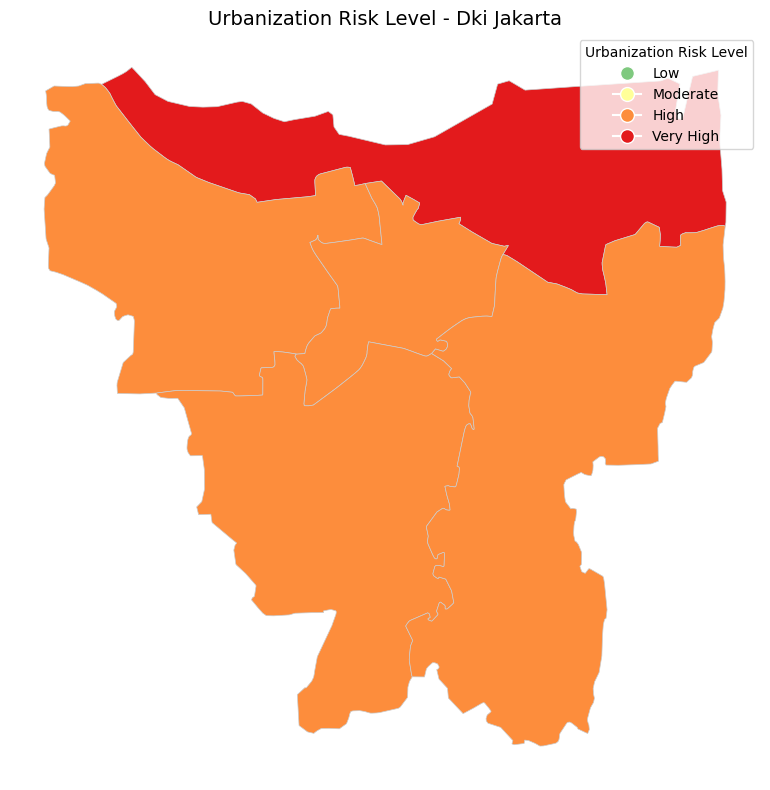

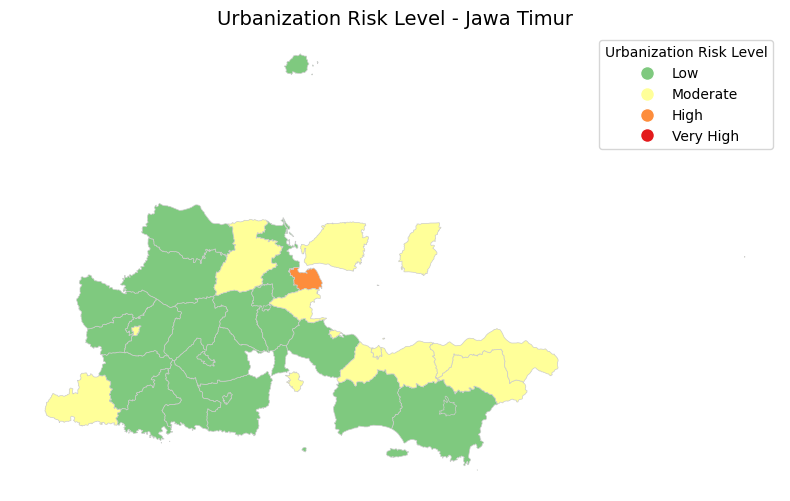

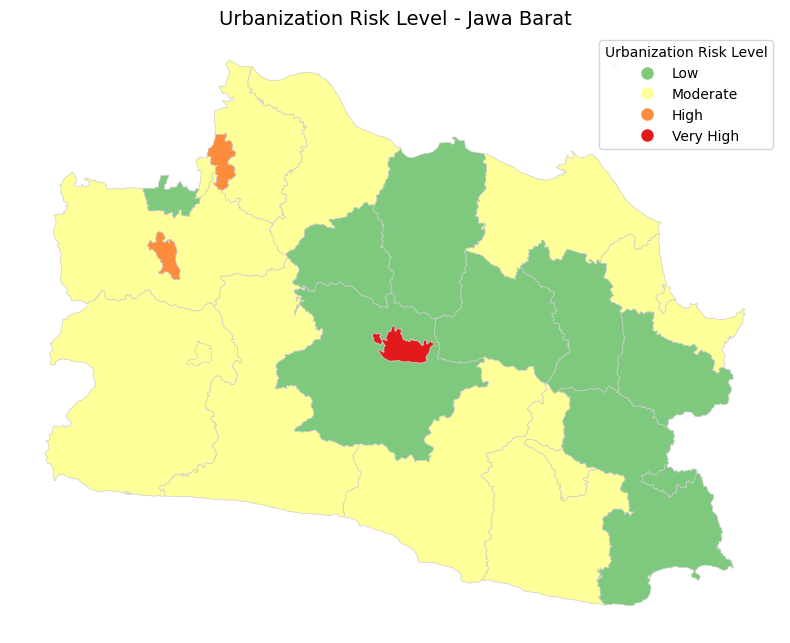

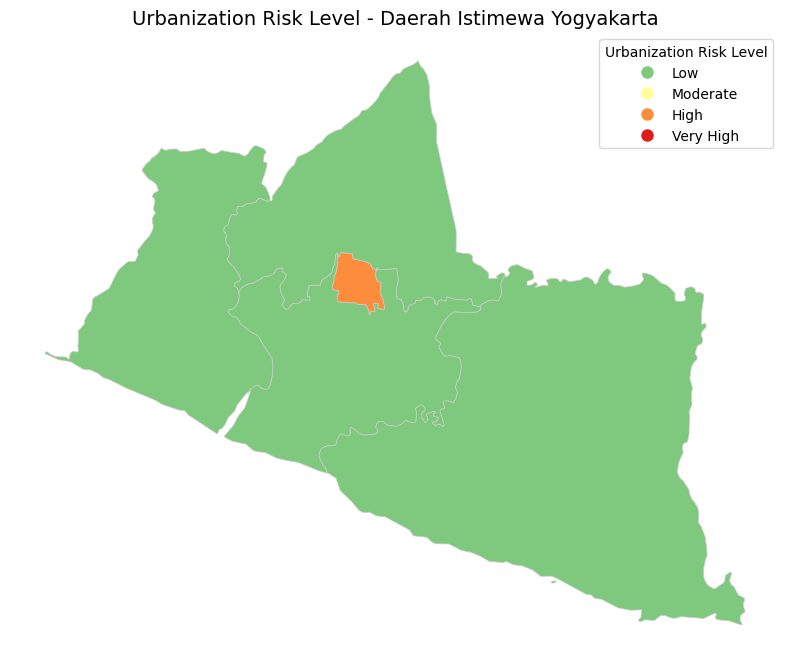

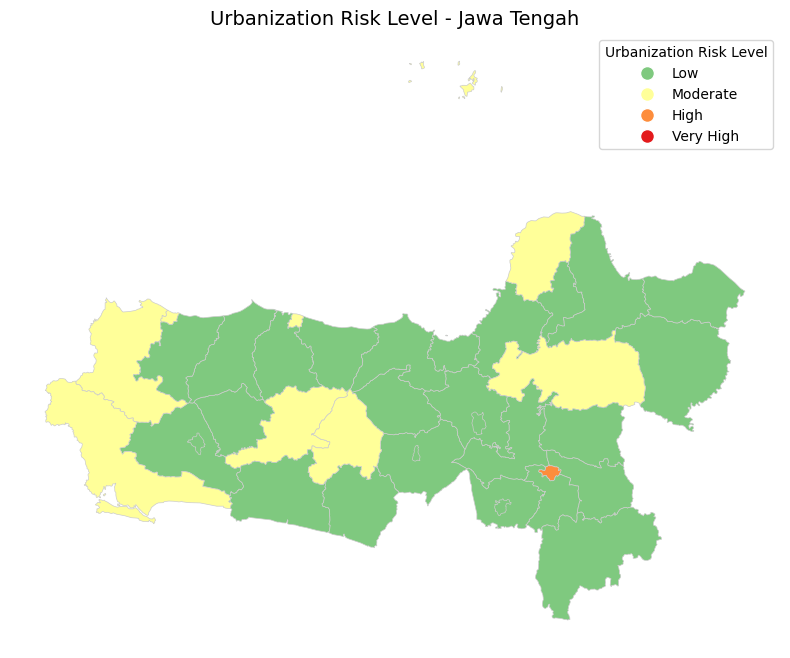

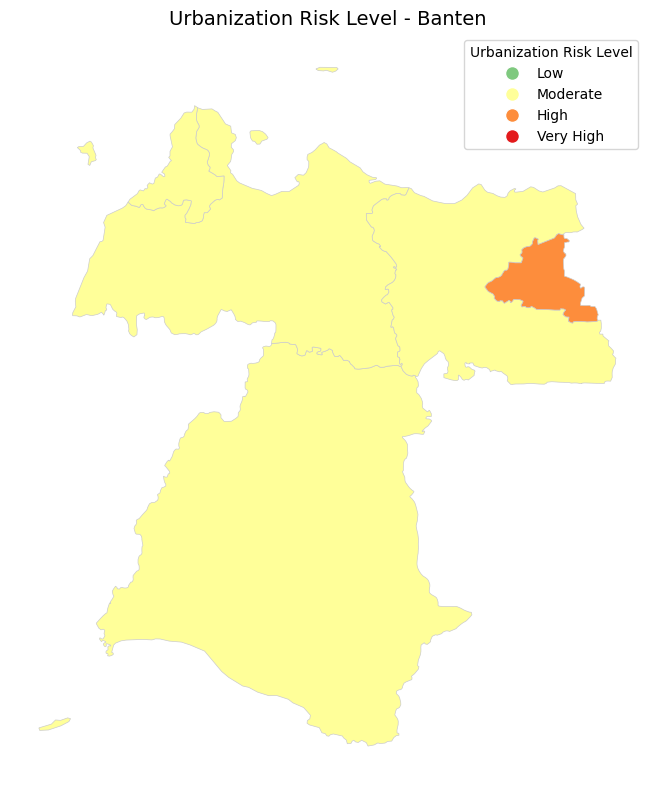

In [25]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

categorical_cols = ['Urban_Pressure_Level', 'Vulnerability_Level', 'Urbanization_Risk_Level']
gdf[categorical_cols] = gdf[categorical_cols].astype('category')

color_maps = {
    'Urban_Pressure_Level': {
        'Low': '#7fc97f',
        'Medium': '#ffff99',
        'High': '#e31a1c'
    },
    'Vulnerability_Level': {
        'Low': '#7fc97f',
        'Medium': '#ffff99',
        'High': '#e31a1c'
    },
    'Urbanization_Risk_Level': {
        'Low': '#7fc97f',
        'Moderate': '#ffff99',
        'High': '#fd8d3c',
        'Very High': '#e31a1c'
    }
}

def plot_risk_map(gdf, column, title, color_mapping, legend_title, ax=None, show=True):
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(10, 10))

    gdf.plot(column=column,
             color=gdf[column].map(color_mapping),
             linewidth=0.5,
             edgecolor='0.8',
             ax=ax,
             legend=False)

    ax.set_title(title, fontsize=14)
    ax.axis('off')

    # Buat custom legend
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label=label,
               markerfacecolor=color, markersize=10)
        for label, color in color_mapping.items()
    ]
    ax.legend(handles=legend_elements, title=legend_title, loc='upper right')

    if show:
        plt.tight_layout()
        plt.show()

for column in color_maps.keys():
    plot_risk_map(
        gdf,
        column=column,
        title=f'Peta {column} di Pulau Jawa',
        color_mapping=color_maps[column],
        legend_title=column
    )

unique_prov = gdf['ADM1_NAME'].unique()
urban_risk_colors = color_maps['Urbanization_Risk_Level']

for prov in unique_prov:
    subset = gdf[gdf['ADM1_NAME'] == prov]
    fig, ax = plt.subplots(1, 1, figsize=(8, 8))

    plot_risk_map(
        gdf=subset,
        column='Urbanization_Risk_Level',
        title=f'Urbanization Risk Level - {prov}',
        color_mapping=urban_risk_colors,
        legend_title='Urbanization Risk Level',
        ax=ax,
        show=False
    )

    plt.tight_layout()
    plt.show()

In [46]:
import geopandas as gpd
from libpysal.weights import KNN
from esda.moran import Moran, Moran_Local
from splot.esda import moran_scatterplot

w = KNN.from_dataframe(gdf, k=5)
w.transform = 'r'

moran_urban = Moran(gdf['Urban_Pressure'], w)
print('Urban_Pressure')
print(f"Moran’s I: {moran_urban.I:.4f}")
print(f"Expected I: {moran_urban.EI:.4f}")
print(f"p-value: {moran_urban.p_sim:.4f}\n")

moran_vul = Moran(gdf['Vulnerability_index'], w)
print('Vulnerability_index')
print(f"Moran’s I: {moran_vul.I:.4f}")
print(f"Expected I: {moran_vul.EI:.4f}")
print(f"p-value: {moran_vul.p_sim:.4f}\n")

lisa_urban = Moran_Local(gdf['Urban_Pressure'], w)
gdf['urban_local_I'] = lisa_urban.Is
gdf['urban_local_p'] = lisa_urban.p_sim
gdf['urban_quadrant'] = lisa_urban.q

lisa_vul = Moran_Local(gdf['Vulnerability_index'], w)
gdf['vul_local_I'] = lisa_vul.Is
gdf['vul_local_p'] = lisa_vul.p_sim
gdf['vul_quadrant'] = lisa_vul.q

Urban_Pressure
Moran’s I: 0.5327
Expected I: -0.0088
p-value: 0.0010

Vulnerability_index
Moran’s I: 0.4209
Expected I: -0.0088
p-value: 0.0010



In [56]:
!pip install adjusttext

Kuadran I (HH): kanan atas

Kuadran II (LH): kiri atas

Kuadran III (LL): kiri bawah

Kuadran IV (HL): kanan bawah

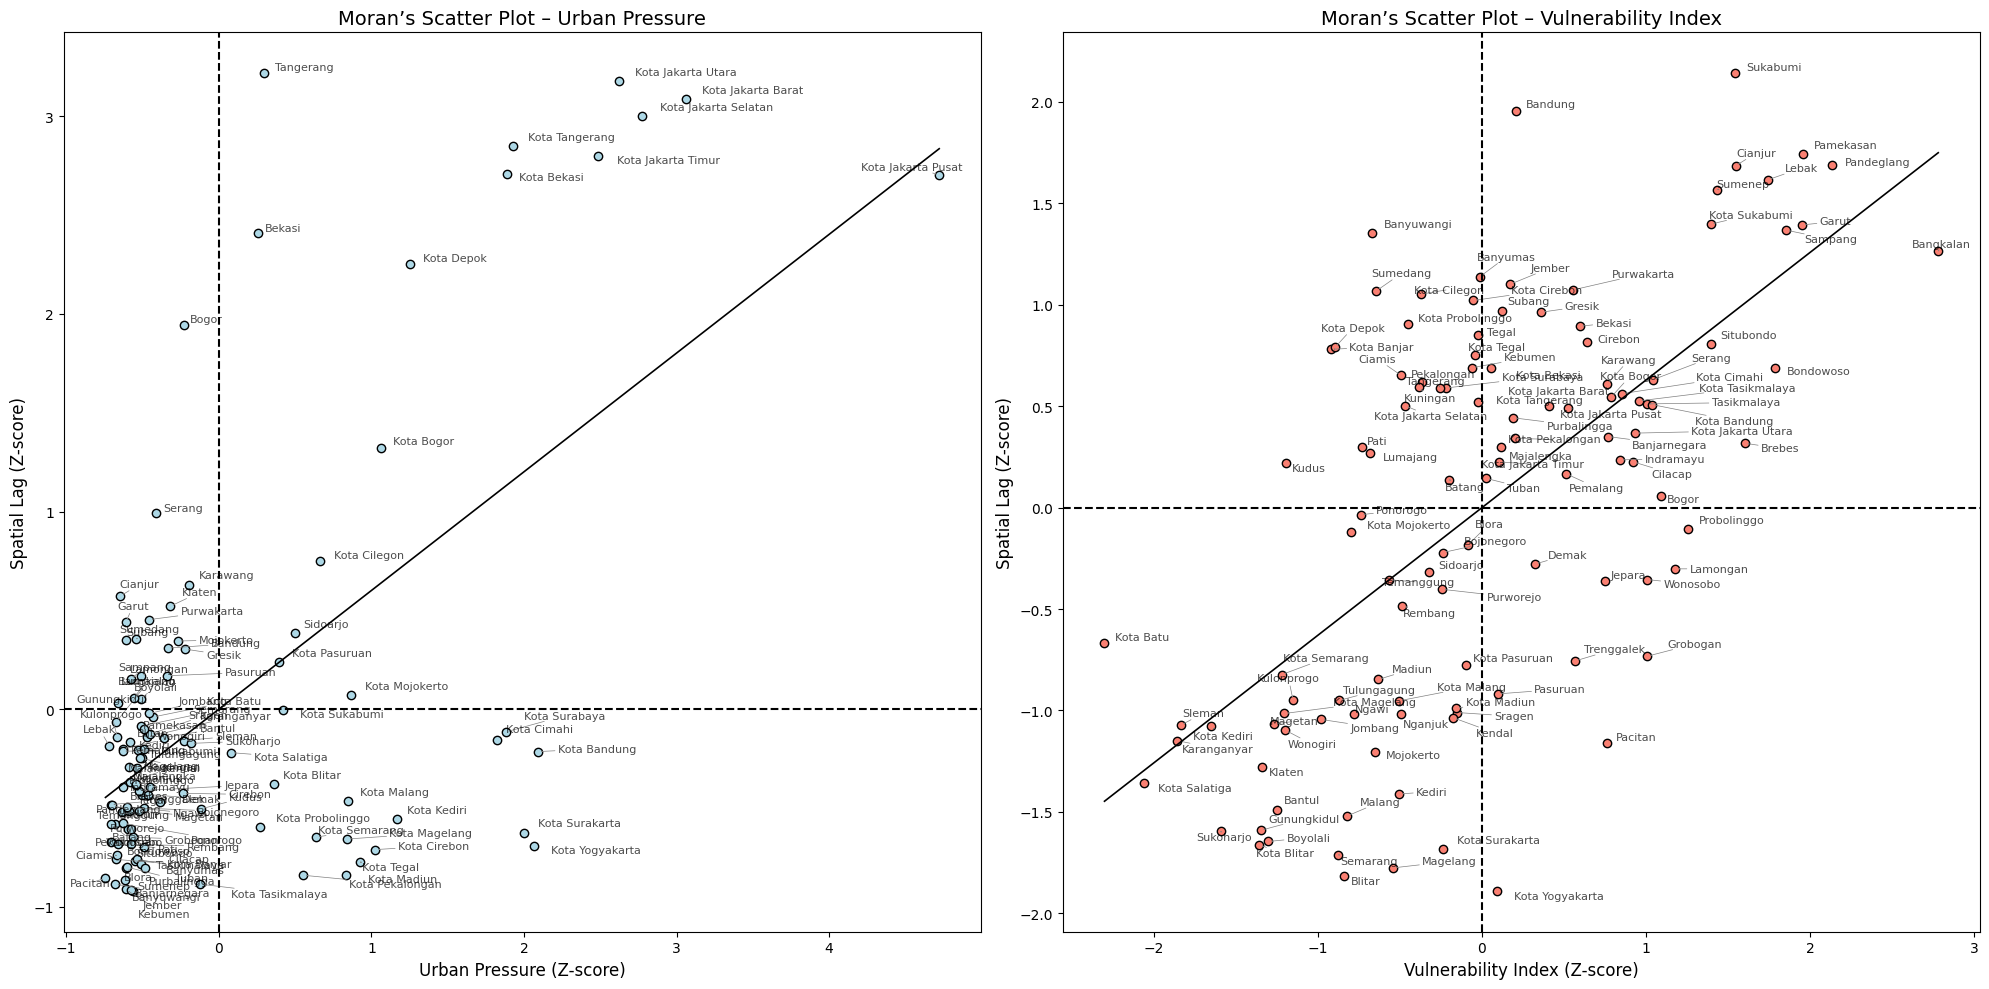

In [72]:
import matplotlib.pyplot as plt
from libpysal.weights import lag_spatial
from scipy import stats
from adjustText import adjust_text
import numpy as np

w.transform = 'r'

# --- Urban Pressure
y1 = gdf['Urban_Pressure']
lag_y1 = lag_spatial(w, y1)
z_y1 = stats.zscore(y1)
z_lag_y1 = stats.zscore(lag_y1)

# --- Vulnerability Index
y2 = gdf['Vulnerability_index']
lag_y2 = lag_spatial(w, y2)
z_y2 = stats.zscore(y2)
z_lag_y2 = stats.zscore(lag_y2)

# --- Subplot
fig, axs = plt.subplots(1, 2, figsize=(20, 10))  # Perbesar area

# --- Plot 1: Urban Pressure
axs[0].scatter(z_y1, z_lag_y1, edgecolor='k', facecolor='lightblue')
axs[0].axhline(0, color='k', linestyle='--')
axs[0].axvline(0, color='k', linestyle='--')

# Tambahkan garis regresi
slope1, intercept1 = np.polyfit(z_y1, z_lag_y1, 1)
x_vals1 = np.linspace(z_y1.min(), z_y1.max(), 100)
axs[0].plot(x_vals1, slope1 * x_vals1 + intercept1, color='black', linestyle='-', linewidth=1.2)

axs[0].set_title('Moran’s Scatter Plot – Urban Pressure', fontsize=14)
axs[0].set_xlabel('Urban Pressure (Z-score)', fontsize=12)
axs[0].set_ylabel('Spatial Lag (Z-score)', fontsize=12)

texts1 = [axs[0].text(z_y1[i], z_lag_y1[i], row['ADM2_NAME'], fontsize=8, alpha=0.7)
          for i, row in gdf.iterrows()]
adjust_text(texts1, ax=axs[0], arrowprops=dict(arrowstyle='->', color='gray', lw=0.5))

# --- Plot 2: Vulnerability Index
axs[1].scatter(z_y2, z_lag_y2, edgecolor='k', facecolor='salmon')
axs[1].axhline(0, color='k', linestyle='--')
axs[1].axvline(0, color='k', linestyle='--')

# Tambahkan garis regresi
slope2, intercept2 = np.polyfit(z_y2, z_lag_y2, 1)
x_vals2 = np.linspace(z_y2.min(), z_y2.max(), 100)
axs[1].plot(x_vals2, slope2 * x_vals2 + intercept2, color='black', linestyle='-', linewidth=1.2)

axs[1].set_title('Moran’s Scatter Plot – Vulnerability Index', fontsize=14)
axs[1].set_xlabel('Vulnerability Index (Z-score)', fontsize=12)
axs[1].set_ylabel('Spatial Lag (Z-score)', fontsize=12)

texts2 = [axs[1].text(z_y2[i], z_lag_y2[i], row['ADM2_NAME'], fontsize=8, alpha=0.7)
          for i, row in gdf.iterrows()]
adjust_text(texts2, ax=axs[1], arrowprops=dict(arrowstyle='->', color='gray', lw=0.5))

plt.tight_layout()
plt.show()


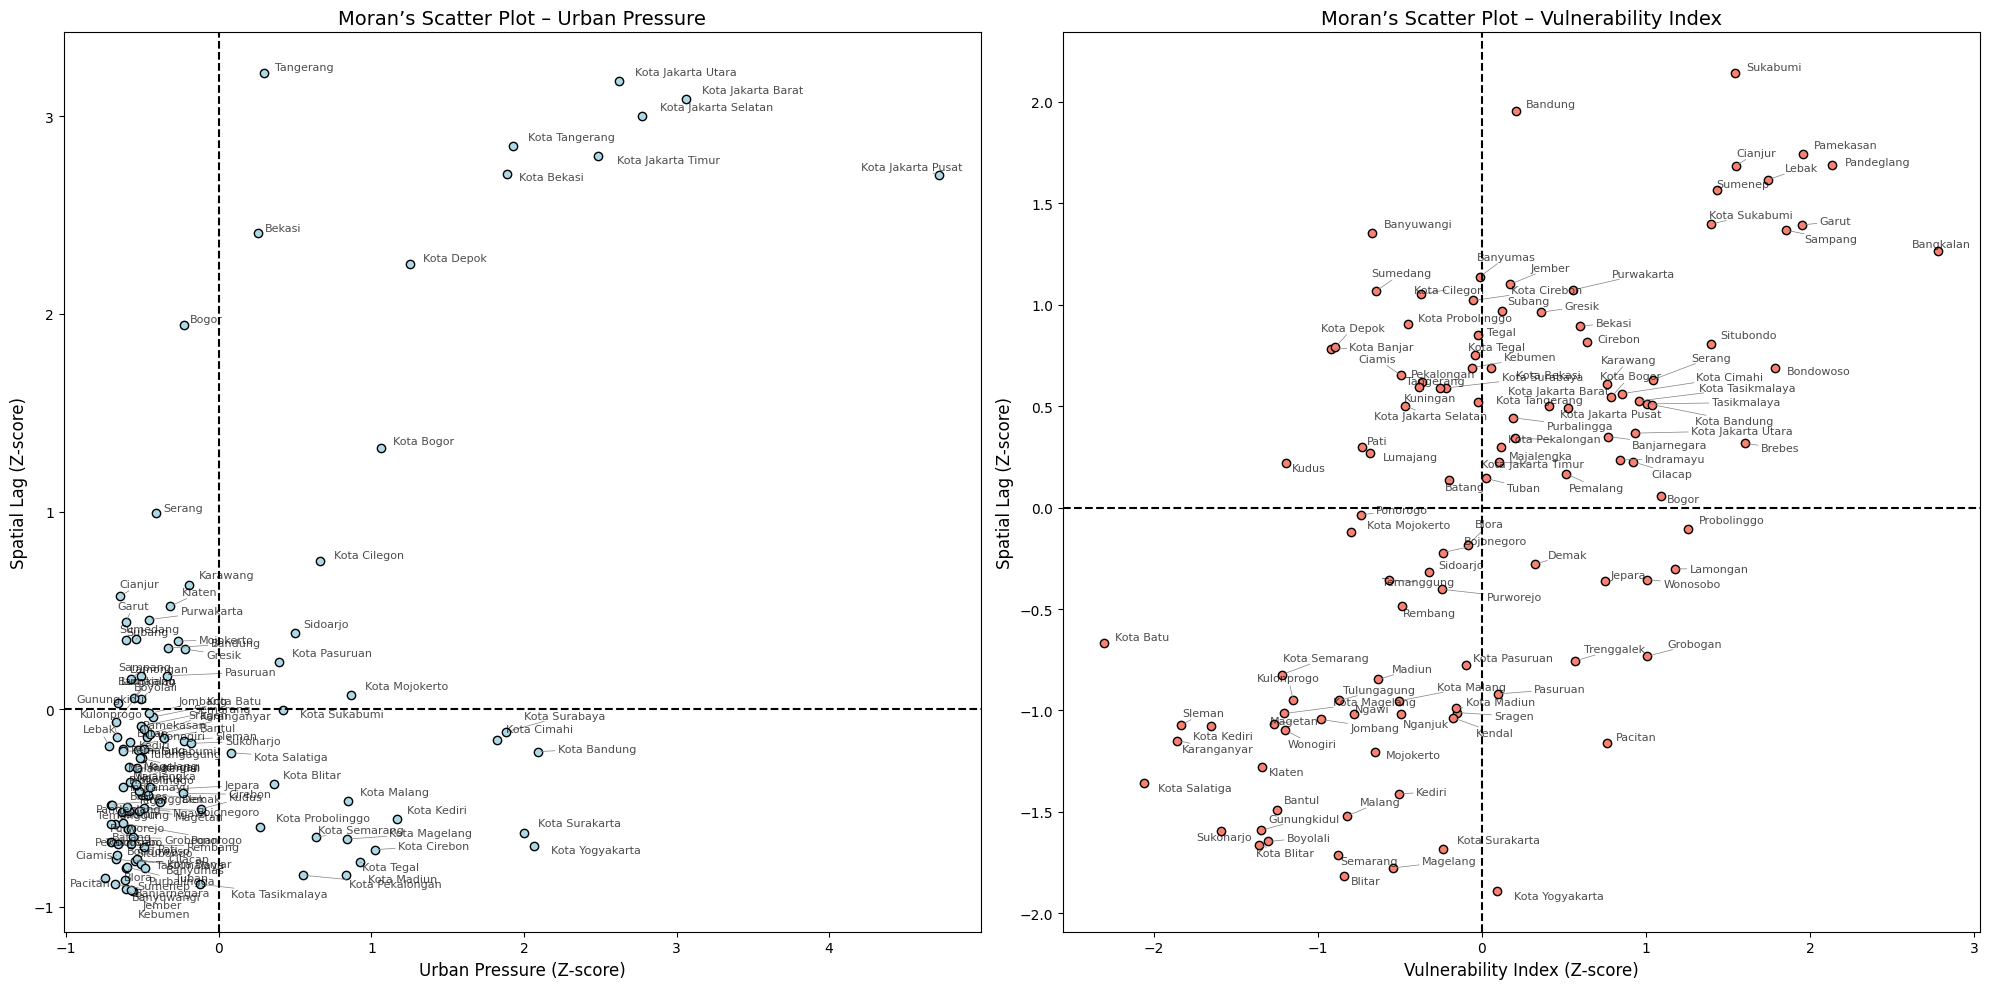

In [58]:
import matplotlib.pyplot as plt
from libpysal.weights import lag_spatial
from scipy import stats
from adjustText import adjust_text

w.transform = 'r'

# --- Urban Pressure
y1 = gdf['Urban_Pressure']
lag_y1 = lag_spatial(w, y1)
z_y1 = stats.zscore(y1)
z_lag_y1 = stats.zscore(lag_y1)

# --- Vulnerability Index
y2 = gdf['Vulnerability_index']
lag_y2 = lag_spatial(w, y2)
z_y2 = stats.zscore(y2)
z_lag_y2 = stats.zscore(lag_y2)

# --- Subplot
fig, axs = plt.subplots(1, 2, figsize=(20, 10))  # Perbesar area

# --- Plot 1: Urban Pressure
axs[0].scatter(z_y1, z_lag_y1, edgecolor='k', facecolor='lightblue')
axs[0].axhline(0, color='k', linestyle='--')
axs[0].axvline(0, color='k', linestyle='--')
axs[0].set_title('Moran’s Scatter Plot – Urban Pressure', fontsize=14)
axs[0].set_xlabel('Urban Pressure (Z-score)', fontsize=12)
axs[0].set_ylabel('Spatial Lag (Z-score)', fontsize=12)

texts1 = [axs[0].text(z_y1[i], z_lag_y1[i], row['ADM2_NAME'], fontsize=8, alpha=0.7) 
          for i, row in gdf.iterrows()]
adjust_text(texts1, ax=axs[0], arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

# --- Plot 2: Vulnerability Index
axs[1].scatter(z_y2, z_lag_y2, edgecolor='k', facecolor='salmon')
axs[1].axhline(0, color='k', linestyle='--')
axs[1].axvline(0, color='k', linestyle='--')
axs[1].set_title('Moran’s Scatter Plot – Vulnerability Index', fontsize=14)
axs[1].set_xlabel('Vulnerability Index (Z-score)', fontsize=12)
axs[1].set_ylabel('Spatial Lag (Z-score)', fontsize=12)

texts2 = [axs[1].text(z_y2[i], z_lag_y2[i], row['ADM2_NAME'], fontsize=8, alpha=0.7)
          for i, row in gdf.iterrows()]
adjust_text(texts2, ax=axs[1], arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

plt.tight_layout()
plt.show()


In [42]:
from esda.moran import Moran_Local

lisa = Moran_Local(gdf['Urban_Pressure'], w)

gdf['local_moran'] = lisa.Is
gdf['local_moran_p'] = lisa.p_sim
gdf['quadrant'] = lisa.q

gdf

,id,ADM0_CODE,ADM0_NAME,ADM1_CODE,ADM1_NAME,ADM2_CODE,ADM2_NAME,DISP_AREA,EXP2_YEAR,STATUS,STR2_YEAR,Shape_Area,Shape_Leng,geometry,Kab/Kota,Urban_Pressure,Urban_Pressure_Level,Vulnerability_index,Vulnerability_Level,Urbanization_Risk_Level,LISA_I,LISA_p,LISA_q,local_moran,local_moran_p,quadrant
0,00010000000000001457,116,Indonesia,1516,Dki Jakarta,73726,Kota Jakarta Utara,NO,3000,Member State,2002,0.0115,0.7541,"POLYGON ((106.82128 -6.13687, 106.82807 -6.135...",Kota Jakarta Utara,0.6016,High,0.4239,High,Very High,0.1154,0.3540,1,7.7516,0.0010,1
1,00010000000000001458,116,Indonesia,1521,Jawa Timur,73709,Kota Batu,NO,3000,Member State,2002,0.0163,0.6561,"POLYGON ((112.47843 -7.76766, 112.47875 -7.768...",Kota Batu,0.0750,Low,0.1629,Low,Low,1.2951,0.0940,3,-0.0564,0.3520,2
2,00010000000000001459,116,Indonesia,1521,Jawa Timur,73780,Malang,NO,3000,Member State,2002,0.2849,4.2360,"POLYGON ((112.68363 -8.45166, 112.68501 -8.453...",Malang,0.0575,Low,0.2822,Low,Low,0.9264,0.0020,3,0.0502,0.4510,3
3,00010000000000001476,116,Indonesia,73613,Jawa Barat,73636,Bandung,NO,3000,Member State,2002,0.2551,4.2702,"POLYGON ((107.47665 -7.25653, 107.47671 -7.254...",Bandung,0.0916,Low,0.3650,Medium,Low,0.2417,0.0030,1,-0.1468,0.1650,2
4,00010000000000001477,116,Indonesia,73613,Jawa Barat,73718,Kota Cimahi,NO,3000,Member State,2002,0.0009,0.1330,"POLYGON ((107.55603 -6.88901, 107.55207 -6.882...",Kota Cimahi,0.4646,High,0.4174,High,Very High,0.2158,0.2740,1,0.0542,0.4030,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,000100000000000013fd,116,Indonesia,73613,Jawa Barat,18025,Subang,NO,3000,Member State,1000,0.1751,2.1853,"POLYGON ((107.85075 -6.57331, 107.85077 -6.573...",Subang,0.0559,Low,0.3584,Medium,Low,0.0646,0.1080,1,-0.2587,0.1690,2
110,000100000000000013fe,116,Indonesia,73613,Jawa Barat,18026,Sukabumi,NO,3000,Member State,1000,0.3395,3.6889,"POLYGON ((106.39705 -6.97776, 106.39935 -6.977...",Sukabumi,0.0407,Low,0.4727,High,Moderate,2.0031,0.0030,1,0.0132,0.4640,3
111,000100000000000013ff,116,Indonesia,73613,Jawa Barat,18027,Sumedang,NO,3000,Member State,1000,0.1273,1.9184,"POLYGON ((108.12906 -7.04076, 108.13176 -7.038...",Sumedang,0.0450,Low,0.2966,Low,Low,-0.3784,0.0980,2,-0.2864,0.1710,2
112,00010000000000001400,116,Indonesia,73613,Jawa Barat,73711,Kota Bekasi,NO,3000,Member State,1000,0.0118,0.6273,"POLYGON ((106.94382 -6.24966, 106.94445 -6.249...",Kota Bekasi,0.4753,High,0.3529,Medium,High,0.0186,0.1970,1,4.8091,0.0010,1


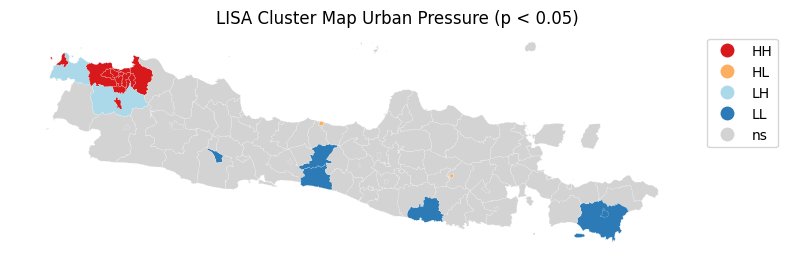

In [27]:
lisa = Moran_Local(gdf['Urban_Pressure'], w)

gdf['LISA_I'] = lisa.Is
gdf['LISA_p'] = lisa.p_sim
gdf['LISA_q'] = lisa.q

fig, ax = plt.subplots(1, figsize=(10, 8))
lisa_cluster(lisa, gdf, p=0.05, ax=ax)
ax.set_title("LISA Cluster Map Urban Pressure (p < 0.05)")
plt.show()


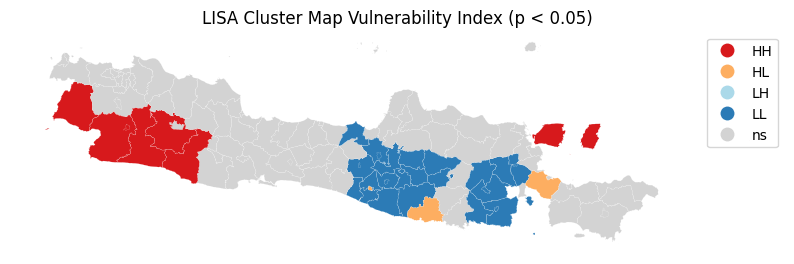

In [28]:
lisa = Moran_Local(gdf['Vulnerability_index'], w)

gdf['LISA_I'] = lisa.Is
gdf['LISA_p'] = lisa.p_sim
gdf['LISA_q'] = lisa.q

fig, ax = plt.subplots(1, figsize=(10, 8))
lisa_cluster(lisa, gdf, p=0.05, ax=ax)
ax.set_title("LISA Cluster Map Vulnerability Index (p < 0.05)")
plt.show()


## Factor Analysis

In [29]:
def factor_detector(df: pd.DataFrame, target: str, features: list, n_class: int = 5) -> pd.DataFrame:
    q_results = []
    for feat in features:
        try:
            df_discrete = pd.qcut(df[feat], n_class, labels=False, duplicates='drop')
        except:
            continue  
        
        df_temp = df[[target]].copy()
        df_temp['X'] = df_discrete
        
        N = len(df_temp)
        sigma2 = df_temp[target].var(ddof=0)
        
        q_val = 1.0
        for cls in df_temp['X'].dropna().unique():
            sub = df_temp[df_temp['X'] == cls]
            Nh = len(sub)
            sigmah2 = sub[target].var(ddof=0)
            q_val -= (Nh / N) * (sigmah2 / sigma2)
        
        q_results.append({
            'Variabel': feat,
            'q_value': q_val
        })
    
    return pd.DataFrame(q_results).sort_values('q_value', ascending=False).reset_index(drop=True)


In [30]:
df_q_pressure = factor_detector(df, target='Urban_Pressure', features=urban_pressure_vars)
df_q_vulnerability = factor_detector(df, target='Vulnerability_index', features=urban_vulnerability_vars)


df_q_pressure['Aspek'] = 'Urban_Pressure'
df_q_vulnerability['Aspek'] = 'Vulnerability'

In [31]:
df_q_pressure.to_excel('q_up.xlsx',index=False)

In [32]:
df_q_vulnerability.to_excel('q_vr.xlsx',index=False)

In [33]:
from itertools import combinations

def interaction_detector(df: pd.DataFrame, target: str, features: list, n_class: int = 5) -> pd.DataFrame:
    results = []
    
    def q_stat(X):
        df_temp = df[[target]].copy()
        df_temp['X'] = X
        N = len(df_temp)
        sigma2 = df_temp[target].var(ddof=0)
        q = 1.0
        for cls in df_temp['X'].dropna().unique():
            sub = df_temp[df_temp['X'] == cls]
            Nh = len(sub)
            sigmah2 = sub[target].var(ddof=0)
            q -= (Nh / N) * (sigmah2 / sigma2)
        return q

    q_individual = {}
    for feat in features:
        try:
            x_disc = pd.qcut(df[feat], n_class, labels=False, duplicates='drop')
            q_individual[feat] = q_stat(x_disc)
        except:
            continue

    for feat1, feat2 in combinations(q_individual.keys(), 2):
        x1 = pd.qcut(df[feat1], n_class, labels=False, duplicates='drop')
        x2 = pd.qcut(df[feat2], n_class, labels=False, duplicates='drop')
        x_comb = x1.astype(str) + '_' + x2.astype(str)
        q_inter = q_stat(x_comb)

        q1 = q_individual[feat1]
        q2 = q_individual[feat2]

        # Tentukan tipe interaksi
        if q_inter < min(q1, q2):
            interaction = 'Nonlinear weakening'
        elif min(q1, q2) < q_inter < max(q1, q2):
            interaction = 'Single-factor nonlinear weakening'
        elif q_inter > max(q1, q2) and q_inter <= q1 + q2:
            interaction = 'Double-factor enhancement'
        elif np.isclose(q_inter, q1 + q2, rtol=1e-2):
            interaction = 'Independent'
        elif q_inter > q1 + q2:
            interaction = 'Nonlinear enhancement'
        else:
            interaction = 'Uncategorized'

        results.append({
            'X1': feat1,
            'X2': feat2,
            'q_X1': q1,
            'q_X2': q2,
            'q_interaction': q_inter,
            'Interaction_Type': interaction
        })

    return pd.DataFrame(results).sort_values('q_interaction', ascending=False).reset_index(drop=True)


In [34]:
interact_pressure = interaction_detector(df, target='Urban_Pressure', features=urban_pressure_vars)
interact_vulnerability = interaction_detector(df, target='Vulnerability_index', features=urban_vulnerability_vars)

In [35]:
interact_vulnerability

,X1,X2,q_X1,q_X2,q_interaction,Interaction_Type
0,X19,X21,0.4997,0.0872,0.7154,Nonlinear enhancement
1,X11,X12,0.4271,0.4622,0.7072,Double-factor enhancement
2,X12,X19,0.4622,0.4997,0.7002,Double-factor enhancement
3,X8,X19,0.2202,0.4997,0.7001,Double-factor enhancement
4,X8,X12,0.2202,0.4622,0.6986,Nonlinear enhancement
...,...,...,...,...,...,...
100,X14,X20,0.0097,0.0485,0.1983,Nonlinear enhancement
101,X20,X21,0.0485,0.0872,0.1946,Nonlinear enhancement
102,X18,X21,0.0119,0.0872,0.1942,Nonlinear enhancement
103,X13,X20,0.0714,0.0485,0.1897,Nonlinear enhancement


In [36]:
interact_pressure

,X1,X2,q_X1,q_X2,q_interaction,Interaction_Type
0,X1,X5,0.7524,0.4671,0.8536,Double-factor enhancement
1,X3,X5,0.7596,0.4671,0.8484,Double-factor enhancement
2,X1,X2,0.7524,0.7556,0.8256,Double-factor enhancement
3,X2,X3,0.7556,0.7596,0.8255,Double-factor enhancement
4,X3,X4,0.7596,0.7006,0.8237,Double-factor enhancement
5,X1,X4,0.7524,0.7006,0.8226,Double-factor enhancement
6,X2,X5,0.7556,0.4671,0.8068,Double-factor enhancement
7,X2,X6,0.7556,0.3478,0.8051,Double-factor enhancement
8,X4,X5,0.7006,0.4671,0.7924,Double-factor enhancement
9,X4,X6,0.7006,0.3478,0.7870,Double-factor enhancement


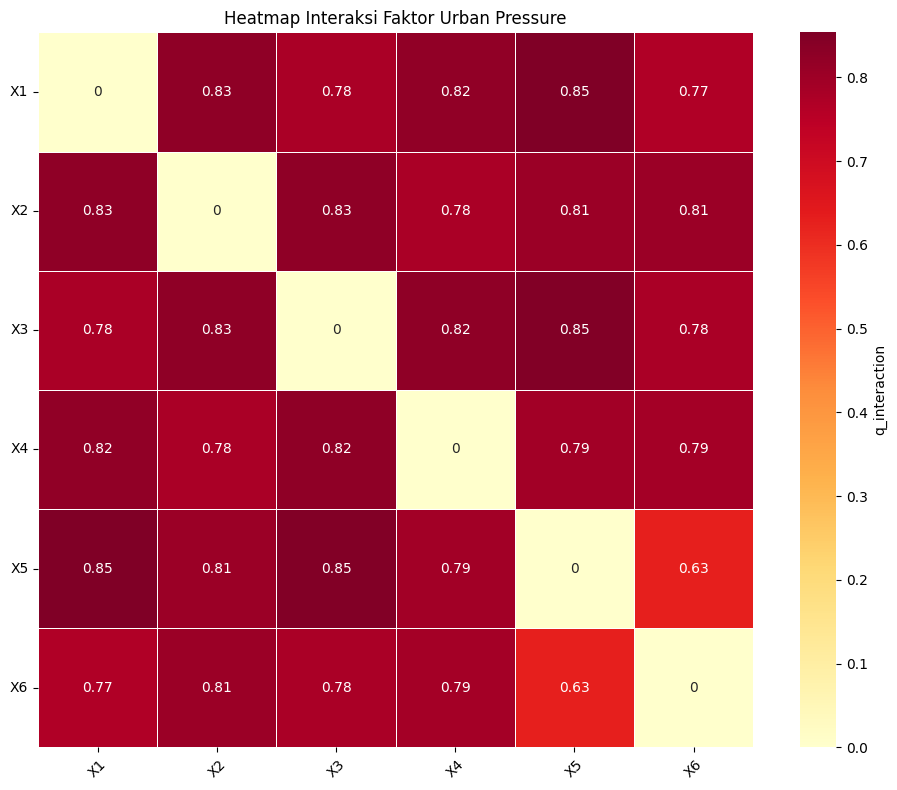

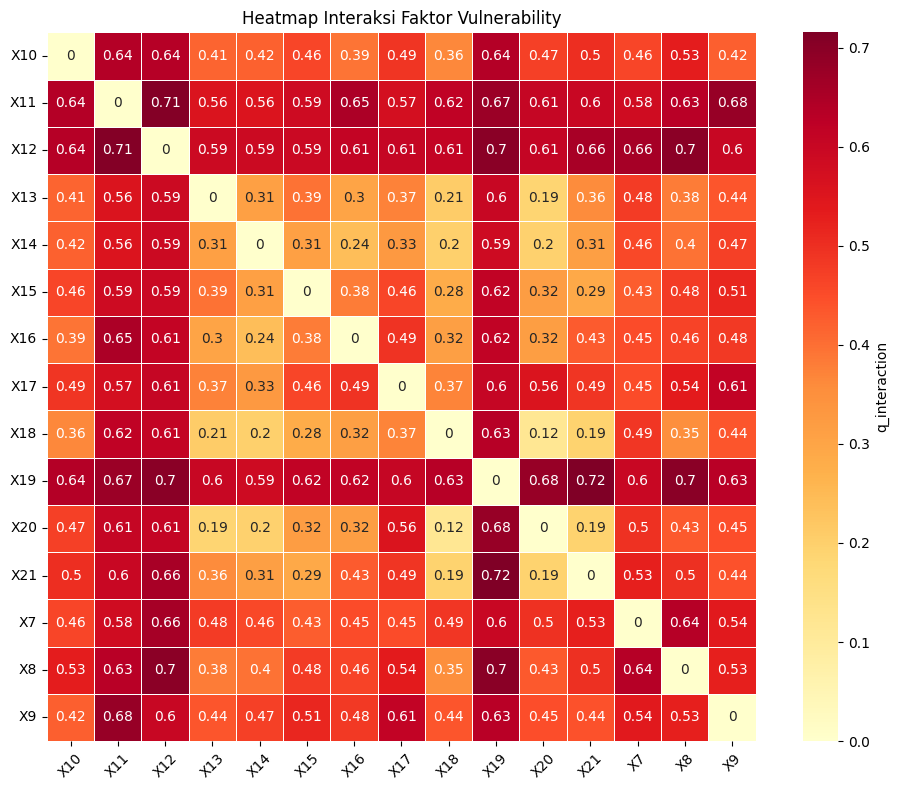

In [37]:
def plot_interaction_heatmap(df_interaction, title):
    features = sorted(set(df_interaction['X1']).union(df_interaction['X2']))
    heatmap_matrix = pd.DataFrame(index=features, columns=features, data=0.0)

    for _, row in df_interaction.iterrows():
        f1, f2 = row['X1'], row['X2']
        q = row['q_interaction']
        heatmap_matrix.loc[f1, f2] = q
        heatmap_matrix.loc[f2, f1] = q

    plt.figure(figsize=(10, 8))
    sns.heatmap(heatmap_matrix, annot=True, cmap="YlOrRd", square=True, linewidths=0.5, cbar_kws={'label': 'q_interaction'})
    plt.title(title)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

plot_interaction_heatmap(interact_pressure, "Heatmap Interaksi Faktor Urban Pressure")
plot_interaction_heatmap(interact_vulnerability, "Heatmap Interaksi Faktor Vulnerability")


In [38]:
df.to_csv('results.csv',index=False)

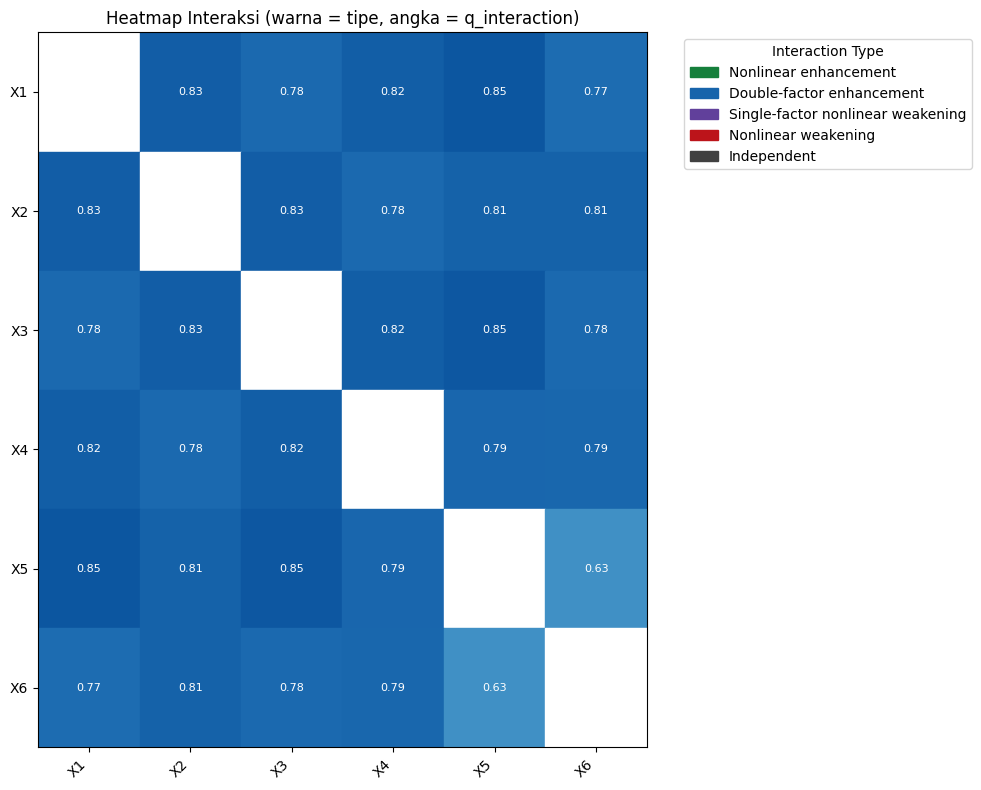

In [71]:
from matplotlib.colors import Normalize, TwoSlopeNorm, to_hex
from matplotlib.cm import ScalarMappable

def plot_gradient_by_interaction_type(df_interaction, title):
    features = sorted(set(df_interaction['X1']).union(df_interaction['X2']))

    # Matriks nilai q dan interaction type
    q_matrix = pd.DataFrame(np.nan, index=features, columns=features)
    type_matrix = pd.DataFrame('', index=features, columns=features)

    for _, row in df_interaction.iterrows():
        x1, x2 = row['X1'], row['X2']
        q_val = row['q_interaction']
        i_type = row['Interaction_Type']
        q_matrix.loc[x1, x2] = q_val
        q_matrix.loc[x2, x1] = q_val
        type_matrix.loc[x1, x2] = i_type
        type_matrix.loc[x2, x1] = i_type

    # Palet warna unik per tipe interaksi
    unique_types = sorted(df_interaction['Interaction_Type'].unique())
    type_to_cmap = {
        'Nonlinear enhancement': 'Greens',
        'Double-factor enhancement': 'Blues',
        'Single-factor nonlinear weakening': 'Purples',
        'Nonlinear weakening': 'Reds',
        'Independent': 'Greys',
    }

    # Bangun color matrix per sel
    color_matrix = pd.DataFrame('', index=features, columns=features)

    for i in features:
        for j in features:
            i_type = type_matrix.loc[i, j]
            q_val = q_matrix.loc[i, j]
            if i_type != '' and pd.notna(q_val):
                cmap_name = type_to_cmap.get(i_type, 'Greys')
                cmap = plt.get_cmap(cmap_name)
                norm = Normalize(vmin=0, vmax=1)  # skala q_interaction: 0–1
                rgba = cmap(norm(q_val))
                color_matrix.loc[i, j] = to_hex(rgba)
            else:
                color_matrix.loc[i, j] = '#FFFFFF'  # warna default putih

    # Plot manual
    fig, ax = plt.subplots(figsize=(10, 8))
    for i, row_label in enumerate(features):
        for j, col_label in enumerate(features):
            value = q_matrix.loc[row_label, col_label]
            color = color_matrix.loc[row_label, col_label]
            ax.add_patch(plt.Rectangle((j, i), 1, 1, color=color))
            if pd.notna(value):
                ax.text(j + 0.5, i + 0.5, f'{value:.2f}',
                        ha='center', va='center', fontsize=8,color='white')

    ax.set_xticks(np.arange(len(features)) + 0.5)
    ax.set_yticks(np.arange(len(features)) + 0.5)
    ax.set_xticklabels(features, rotation=45, ha='right')
    ax.set_yticklabels(features)
    ax.set_xlim(0, len(features))
    ax.set_ylim(0, len(features))
    ax.invert_yaxis()
    ax.set_title(title)

    # Legend manual per Interaction_Type
    from matplotlib.patches import Patch
    legend_patches = [Patch(color=plt.get_cmap(cmap)(0.8), label=itype) for itype, cmap in type_to_cmap.items()]
    ax.legend(handles=legend_patches, bbox_to_anchor=(1.05, 1), loc='upper left', title='Interaction Type')

    plt.tight_layout()
    plt.show()

# Contoh pemanggilan
plot_gradient_by_interaction_type(interact_pressure, "Heatmap Interaksi (warna = tipe, angka = q_interaction)")


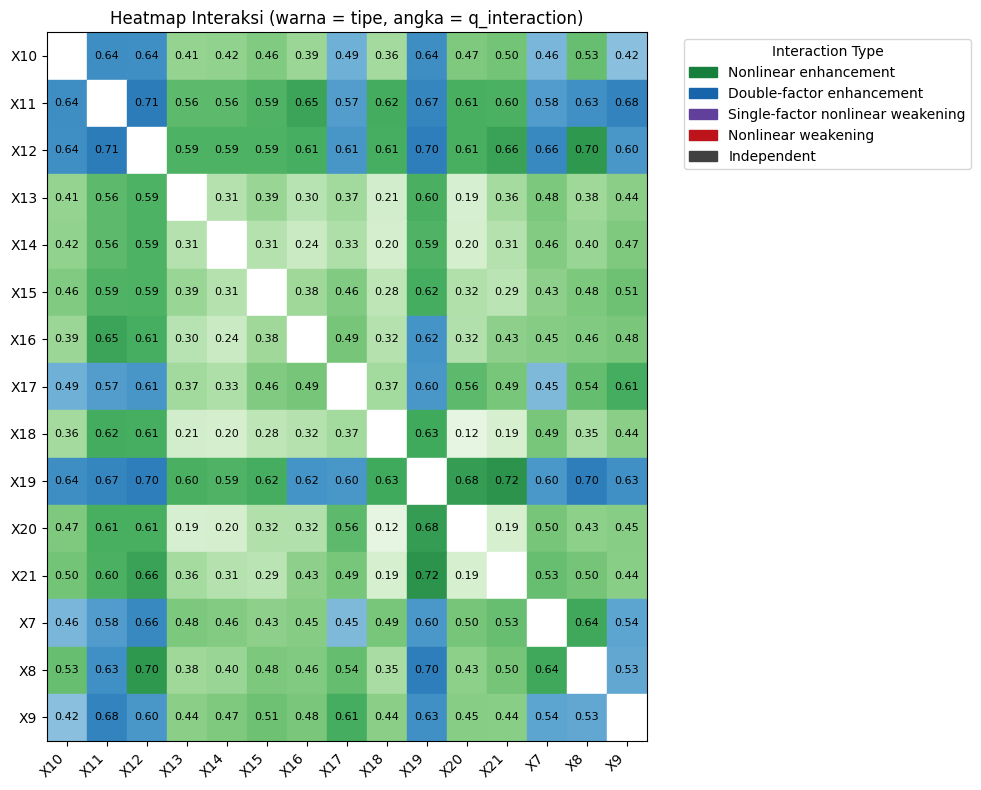

In [70]:
plot_gradient_by_interaction_type(interact_vulnerability, "Heatmap Interaksi (warna = tipe, angka = q_interaction)")
